# NQS (Neural Quantum States) — Google Colab GPU Runner

### Quick Start:
1. **Enable GPU**: Go to **`Runtime` -> `Change runtime type`** and select **`T4 GPU`** (or **`L4` / `A100`** for larger lattices). Enable **Background execution** if available so runs survive local disconnects.
2. **Configure W&B Secret (No Google Drive needed)**: Open the **Secrets** key icon in the left sidebar, add `WANDB_API_KEY` (from https://wandb.ai/authorize), and grant notebook access. Checkpoints and live energy curves sync automatically to W&B.
3. **Run All**: Click **`Runtime` -> `Run all`**. Enable `AUTO_DISCONNECT_WHEN_DONE` in Cell 4 for unattended runs so Colab releases the GPU immediately after finishing.

In [ ]:
# @title 1. Check GPU hardware and install matched JAX / Flax / NetKet dependencies
import shutil
import subprocess
import sys

has_gpu = shutil.which("nvidia-smi") is not None
netket_pkg = "netket[cuda]" if has_gpu else "netket"
if has_gpu:
    print("NVIDIA GPU detected! Installing upgraded CUDA-enabled NetKet + Flax stack...")
else:
    print("WARNING: No GPU detected (switch via Runtime -> Change runtime type -> T4 GPU). Installing CPU stack...")

# Always upgrade flax & optax alongside netket so they match the installed JAX version.
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "--upgrade",
    netket_pkg, "flax", "optax", "wandb", "pyyaml", "matplotlib",
])

try:
    import jax
    import flax
    import netket as nk
except ImportError as exc:
    raise RuntimeError(
        "Packages were upgraded in an already-loaded Python session. "
        "Click 'Runtime -> Restart session' and run again!"
    ) from exc

print(f"JAX    : {jax.__version__} | Devices: {jax.devices()}")
print(f"Flax   : {flax.__version__}")
print(f"NetKet : {nk.__version__}")

NVIDIA GPU detected! Installing upgraded CUDA-enabled NetKet + Flax stack...


ERROR:jax._src.xla_bridge:Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 495, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cuda12/__init__.py", line 373, in initialize
    c_api = xb.register_plugin(
        'cuda', priority=500, library_path=str(path), options=options
    )
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 637, in register_plugin
    c_api = xla_client.load_pjrt_plugin_dynamically(plugin_name, library_path)
  File "/usr/local/lib/python3.13/dist-packages/jaxlib/xla_client.py", line 115, in load_pjrt_plugin_dynamically
    return _xla.load_pjrt_plugin(plugin_name, library_path, c_api=None)
           ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
jax.errors.JaxRuntimeEr

JAX    : 0.11.1 | Devices: [CudaDevice(id=0)]
Flax   : 0.12.12
NetKet : 3.23.0


In [ ]:
# @title 2. Clone or pull latest NQS repository and register package path
import importlib
import os
import subprocess
import sys

REPO_URL = "https://github.com/jiahao116/NQS.git"  # @param {type:"string"}
BRANCH = "main"  # @param {type:"string"}
WORK_DIR = "/content/NQS"
SRC_DIR = os.path.join(WORK_DIR, "src")

if not os.path.exists(WORK_DIR):
    subprocess.check_call(["git", "clone", "-b", BRANCH, REPO_URL, WORK_DIR])
else:
    subprocess.check_call(["git", "-C", WORK_DIR, "pull", "origin", BRANCH])

os.chdir(WORK_DIR)

# Register src/ directly on sys.path so the running IPython kernel finds `nqs`
# immediately without requiring a Colab runtime restart (PEP 660 .pth quirk).
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--no-build-isolation", "-e", "."])
importlib.invalidate_caches()

import nqs
print(f"Repository ready at: {os.getcwd()}")
print(f"Imported nqs from  : {nqs.__file__}")

Repository ready at: /content/NQS
Imported nqs from  : /content/NQS/src/nqs/__init__.py


In [ ]:
# @title 3. Configure W&B telemetry and cloud checkpoints (Drive-free by default)
import os

USE_WANDB = True            # @param {type:"boolean"}
MOUNT_GOOGLE_DRIVE = False  # @param {type:"boolean"}

if MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CHECKPOINT_DIR = "/content/drive/MyDrive/NQS_checkpoints"
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    print(f"Checkpoints will be saved to Google Drive: {CHECKPOINT_DIR}")
else:
    CHECKPOINT_DIR = "/content/NQS/checkpoints"
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    print("Drive-free mode: checkpoints sync automatically to W&B Artifacts.")

if USE_WANDB:
    try:
        from google.colab import userdata
        api_key = userdata.get("WANDB_API_KEY")
        if api_key:
            os.environ["WANDB_API_KEY"] = api_key
            print("Loaded WANDB_API_KEY from Colab Secrets.")
    except Exception:
        pass
    if not os.environ.get("WANDB_API_KEY"):
        import wandb
        wandb.login()

Drive-free mode: checkpoints sync automatically to W&B Artifacts.


[NQS] Experiment : tfim1d_L12_transformer
[NQS] JAX Devices: [CudaDevice(id=0)] (default backend: gpu)
[NQS] System     : tfim_1d | N=12 spins
[NQS] Ansatz     : GPT | Samples/step=1024
[Exact ED] Ground State E0 = -15.32259515
[Exact ED] Energy Gap  dE  = 0.13108693
[Model] Total variational parameters: 17,698
[Step   10/400] E = -14.602026 ± 0.035896 | Var = 1.7429e+00 | V-score = 9.809e-02 | rel_err=4.70e-02 (1213.5 ms/step)
[Step   20/400] E = -14.793429 ± 0.045183 | Var = 1.4524e+00 | V-score = 7.964e-02 | rel_err=3.45e-02 (122.0 ms/step)
[Step   30/400] E = -14.753609 ± 0.044371 | Var = 1.6110e+00 | V-score = 8.881e-02 | rel_err=3.71e-02 (122.6 ms/step)
[Step   40/400] E = -14.766982 ± 0.031701 | Var = 1.5813e+00 | V-score = 8.702e-02 | rel_err=3.63e-02 (122.7 ms/step)
[Step   50/400] E = -14.820641 ± 0.043341 | Var = 1.5214e+00 | V-score = 8.312e-02 | rel_err=3.28e-02 (122.7 ms/step)
[Step   60/400] E = -14.766533 ± 0.044402 | Var = 1.4344e+00 | V-score = 7.894e-02 | rel_err=3.6

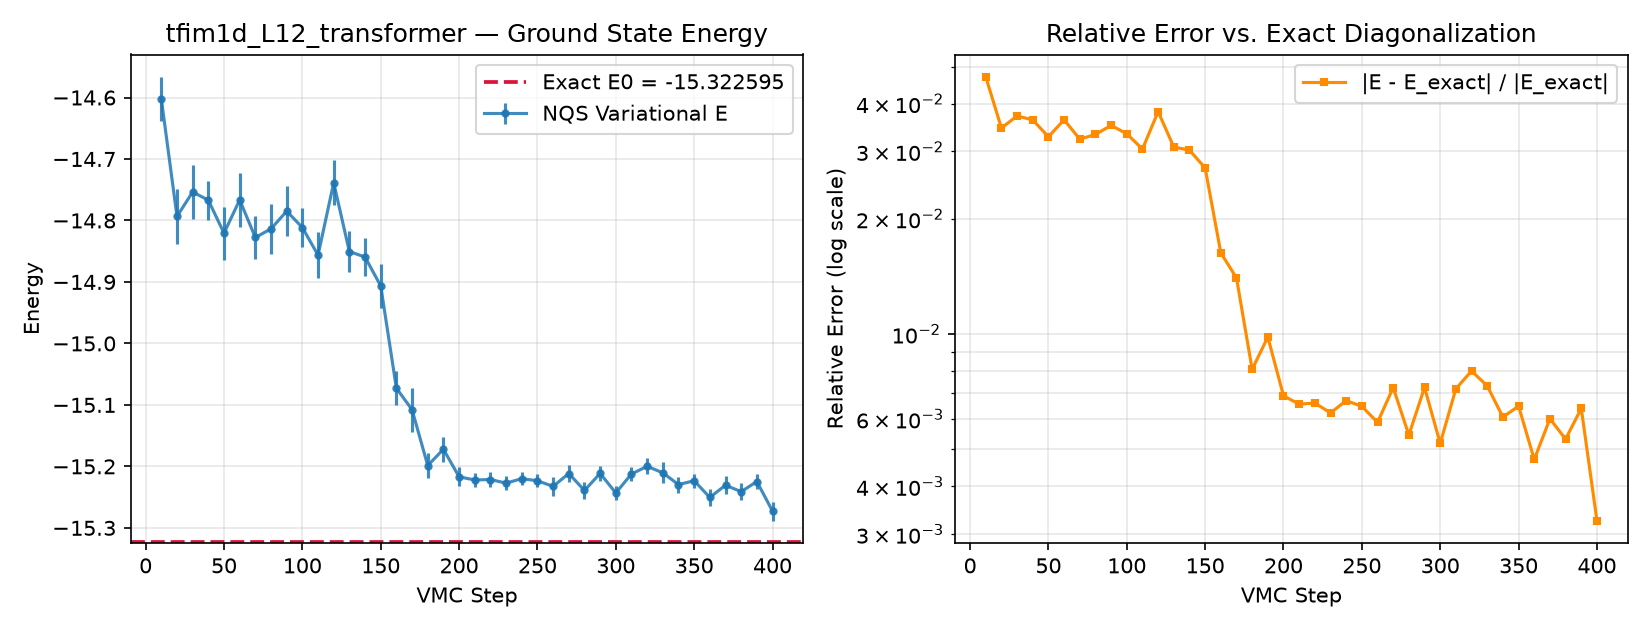

In [ ]:
# @title 4. Run or resume NQS experiment and render convergence plot
import os
import sys
import time
from IPython.display import Image, display

WORK_DIR = "/content/NQS"
SRC_DIR = os.path.join(WORK_DIR, "src")
if os.path.isdir(WORK_DIR):
    os.chdir(WORK_DIR)
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from nqs.config import load_config
from nqs.train import run_experiment

# Available experiment configs:
# - configs/tfim_1d_rbm.yaml       (Classic starter: 1D Critical TFIM + RBM + SR)
# - configs/tfim_1d_gpt.yaml       (Autoregressive: 1D Critical TFIM + Causal Transformer)
# - configs/heisenberg_1d_gpt.yaml (Advanced: 1D Heisenberg + Complex-Phase Transformer)
CONFIG_PATH = "configs/tfim_1d_gpt.yaml"  # @param ["configs/tfim_1d_rbm.yaml", "configs/tfim_1d_gpt.yaml", "configs/heisenberg_1d_gpt.yaml"]
FRESH_START = True                 # @param {type:"boolean"}
AUTO_DISCONNECT_WHEN_DONE = False   # @param {type:"boolean"}

cfg = load_config(CONFIG_PATH)
summary = run_experiment(
    cfg=cfg,
    checkpoint_dir_override=CHECKPOINT_DIR,
    no_wandb=not USE_WANDB,
    fresh_start=FRESH_START,
)

plot_path = summary.get("plot_path")
if plot_path:
    display(Image(filename=plot_path))

if AUTO_DISCONNECT_WHEN_DONE:
    print("Metrics and checkpoints uploaded. Releasing Colab runtime in 5 seconds...")
    time.sleep(5)
    from google.colab import runtime
    runtime.unassign()

In [ ]:
!pip show jax jaxlib flax netket optax

Name: jax
Version: 0.11.1
Summary: Differentiate, compile, and transform Numpy code.
Home-page: https://github.com/jax-ml/jax
Author: JAX team
Author-email: jax-dev@google.com
License: Apache-2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: jaxlib, ml_dtypes, numpy, opt_einsum, scipy
Required-by: dopamine_rl, equinox, flax, NetKet, optax, orbax-checkpoint
---
Name: jaxlib
Version: 0.11.1
Summary: XLA library for JAX
Home-page: https://github.com/jax-ml/jax
Author: JAX team
Author-email: jax-dev@google.com
License: Apache-2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: ml_dtypes, numpy, scipy
Required-by: dopamine_rl, jax, optax
---
Name: flax
Version: 0.12.12
Summary: Flax: A neural network library for JAX designed for flexibility
Home-page: https://github.com/google/flax
Author: 
Author-email: Flax team <flax-dev@google.com>
License: 
Location: /usr/local/lib/python3.13/dist-packages
Requires: jax, msgpack, numpy, optax, orbax-checkpoint, PyYAML, rich, t

In [ ]:

import importlib.metadata, pathlib
print("=== netket requires ===")
print("\n".join(importlib.metadata.requires("netket")))
print("\n=== installed jax/flax/netket packages ===")
!pip list | grep -iE "jax|flax|netket|optax|plum|cuda"
print("\n=== netket/utils/numbers.py ===")
print(pathlib.Path("/usr/local/lib/python3.13/dist-packages/netket/utils/numbers.py").read_text())

=== netket requires ===
einops>=0.8.1
equinox>=0.12.2
flax>=0.10.6
igraph>=0.10.0
jax>=0.7.0
numba>=0.59
numpy<3.0,>=1.20
optax<0.3,>=0.2.2
orjson<4,>=3.10.7
plum-dispatch>=2.4
rich>=12.0
scipy<2,>=1.5.3
sparse>=0.12.0
tqdm<5,>=4.60
jax[cuda12]; (sys_platform == 'linux') and extra == 'cuda'
black==25.1.0; extra == 'dev'
build>=1; extra == 'dev'
coverage>=5; extra == 'dev'
matplotlib>=3; extra == 'dev'
networkx>=2.4; extra == 'dev'
pre-commit>=2.7; extra == 'dev'
pytest-cov>=2.10.1; extra == 'dev'
pytest-json-report>=1.3; extra == 'dev'
pytest-xdist[psutil]>=2; extra == 'dev'
pytest>=6; extra == 'dev'
qutip>=5; extra == 'dev'
ruff==0.14.1; extra == 'dev'
wheel>=0.38.1; extra == 'dev'
ipywidgets>=8.1.7; extra == 'docs'
myst-nb<1.5,>=1.0; extra == 'docs'
myst-parser<5.2.0,>=2.0.0; extra == 'docs'
nbconvert>=7.16.6; extra == 'docs'
sphinx-autodoc-typehints<4.0,>=1.22; extra == 'docs'
sphinx-book-theme<1.5,>=1.1; extra == 'docs'
sphinx-copybutton>=0.5.2; extra == 'docs'
sphinx-design>=0.4.0

In [ ]:

!pip uninstall -y -q jax-cuda12-plugin jax-cuda12-pjrt
!pip install -q "plum-dispatch<2.8"
!pip show plum-dispatch

Name: plum-dispatch
Version: 2.7.1
Summary: Multiple dispatch in Python
Home-page: 
Author: 
Author-email: Wessel Bruinsma <wessel.p.bruinsma@gmail.com>
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: beartype, rich, typing-extensions
Required-by: fastai, fasttransform, NetKet


In [ ]:

!pip show plum-dispatch beartype
import plum, beartype
print("loaded:", plum.__version__, beartype.__version__)

Name: plum-dispatch
Version: 2.7.1
Summary: Multiple dispatch in Python
Home-page: 
Author: 
Author-email: Wessel Bruinsma <wessel.p.bruinsma@gmail.com>
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: beartype, rich, typing-extensions
Required-by: fastai, fasttransform, NetKet
---
Name: beartype
Version: 0.23.1
Summary: Unbearably fast near-real-time pure-Python runtime-static type-checker.
Home-page: 
Author: 
Author-email: Cecil Curry <leycec@gmail.com>
License-Expression: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: 
Required-by: plum-dispatch
loaded: 2.7.1 0.23.1


In [ ]:

!pip install -q "beartype<0.23"
!pip show beartype plum-dispatch

Name: beartype
Version: 0.22.9
Summary: Unbearably fast near-real-time pure-Python runtime-static type-checker.
Home-page: 
Author: 
Author-email: Cecil Curry <leycec@gmail.com>
License: MIT License

Copyright (c) 2014-2025 Beartype authors.

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRING

In [ ]:

import inspect, netket as nk
print("VMC methods:", [m for m in dir(nk.driver.VMC) if not m.startswith("_")])
print("VMC.run sig:", inspect.signature(nk.driver.VMC.run))
print("VMC.advance sig:", inspect.signature(nk.driver.VMC.advance) if hasattr(nk.driver.VMC, "advance") else None)

VMC methods: ['compute_loss_and_update', 'energy', 'estimate', 'info', 'optimizer', 'preconditioner', 'replace', 'reset', 'reset_step', 'run', 'state', 'step_count', 'update_parameters']
VMC.run sig: (self, n_iter: int, out: collections.abc.Iterable[netket._src.logging.base.AbstractLog] | None = (), obs: dict[str, netket.operator._abstract_observable.AbstractObservable] | None = None, step_size: int = 1, show_progress: bool = True, save_params_every: int = 50, write_every: int = 50, callback: Union[Callable[[int, dict, ForwardRef('AbstractDriver')], bool], netket._src.callbacks.base.AbstractCallback, NoneType] = None, timeit: bool = False, _graceful_keyboard_interrupt: bool = True)
VMC.advance sig: None
